# Travelling Salesman Problem: Genetic Algorithm vs Particle Swarm Optimization

Shortest round trip through 10 Malaysian cities, solved with a GA and a discrete PSO, compared over 5 runs.

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from math import sqrt
from copy import deepcopy
import time
from collections import defaultdict


# 1. PROBLEM SETUP - MALAYSIAN CITIES TSP

# Malaysian cities with coordinates (longitude, latitude)
cities = {
    0: {"name": "Kuala Lumpur", "coords": (101.6869, 3.1390)},
    1: {"name": "George Town", "coords": (100.3292, 5.4145)},
    2: {"name": "Johor Bahru", "coords": (103.7414, 1.4927)},
    3: {"name": "Ipoh", "coords": (101.0901, 4.5975)},
    4: {"name": "Kuching", "coords": (110.3549, 1.5397)},
    5: {"name": "Kota Kinabalu", "coords": (116.0735, 5.9804)},
    6: {"name": "Shah Alam", "coords": (101.5185, 3.0733)},
    7: {"name": "Malacca City", "coords": (102.2501, 2.1896)},
    8: {"name": "Alor Setar", "coords": (100.3697, 6.1216)},
    9: {"name": "Miri", "coords": (113.9914, 4.3995)}
}

In [2]:
# Calculate distance matrix
num_cities = len(cities)
distance_matrix = np.zeros((num_cities, num_cities))
for i in range(num_cities):
    for j in range(num_cities):
        lon1, lat1 = cities[i]["coords"]
        lon2, lat2 = cities[j]["coords"]
        distance_matrix[i][j] = sqrt((lon2-lon1)**2 + (lat2-lat1)**2) * 111  # 1° ≈ 111km


In [3]:
# 2. GENETIC ALGORITHM IMPLEMENTATION

def create_individual():
    """Create a random valid route (individual)"""
    ind = list(range(num_cities))
    random.shuffle(ind)
    ind.append(ind[0])  # Complete the loop
    return ind

def calculate_fitness(route):
    """Calculate total distance of a route"""
    total = 0
    for i in range(len(route)-1):
        total += distance_matrix[route[i]][route[i+1]]
    return total

def tournament_selection(population, k=3):
    """Select best from random tournament"""
    tournament = random.sample(population, k)
    return min(tournament, key=lambda x: calculate_fitness(x))

def ordered_crossover(p1, p2):
    """OX crossover for TSP"""
    size = len(p1)
    start, end = sorted(random.sample(range(size-1), 2))
    
    # Initialize child with None values
    child = [None]*(size-1)
    
    # Copy segment from parent1
    child[start:end] = p1[start:end]
    
    # Fill remaining from parent2
    remaining = [item for item in p2[:-1] if item not in child[start:end]]
    ptr = 0
    for i in range(size-1):
        if child[i] is None:
            child[i] = remaining[ptr]
            ptr += 1
    child.append(child[0])  # Complete loop
    return child

def swap_mutation(route, mutation_rate=0.1):
    """Swap two cities in the route"""
    if random.random() < mutation_rate and len(route) > 3:
        i, j = random.sample(range(1, len(route)-1), 2)
        route[i], route[j] = route[j], route[i]
    return route

def genetic_algorithm(pop_size=100, max_gens=500, conv_thresh=1.0, verbose=False):
    """Complete GA implementation with convergence tracking"""
    pop = [create_individual() for _ in range(pop_size)]
    best_route = None
    best_dist = float('inf')
    history = []
    conv_gen = max_gens
    
    for gen in range(max_gens):
        # Evaluate population
        new_pop = []
        current_best = min(pop, key=lambda x: calculate_fitness(x))
        current_dist = calculate_fitness(current_best)
        
        # Update global best
        if current_dist < best_dist:
            improvement = best_dist - current_dist
            best_dist = current_dist
            best_route = deepcopy(current_best)
            
            # Check convergence
            if improvement < conv_thresh:
                if gen - conv_gen > 10:  # Stable for 10 gens
                    conv_gen = gen
                    if verbose:
                        print(f"Converged at generation {gen}")
                    break
            else:
                conv_gen = gen
        history.append(best_dist)
        
        # Elitism: keep best individual
        new_pop.append(deepcopy(current_best))
        
        # Create offspring
        while len(new_pop) < pop_size:
            parent1 = tournament_selection(pop)
            parent2 = tournament_selection(pop)
            child = ordered_crossover(parent1[:-1], parent2[:-1])
            child = swap_mutation(child)
            
            # Ensure valid route
            if len(set(child[:-1])) == num_cities:
                new_pop.append(child)
            else:
                new_pop.append(create_individual())
        
        pop = new_pop
    
    return best_route, best_dist, conv_gen, history

In [4]:
# 3. PARTICLE SWARM OPTIMIZATION IMPLEMENTATION

class Particle:
    def __init__(self, route):
        self.position = route
        self.velocity = []  # List of swap operations
        self.best_position = deepcopy(route)
        self.best_distance = calculate_fitness(route)
        
    def update_position(self):
        """Apply velocity swaps to position"""
        for (i,j) in self.velocity:
            if i < len(self.position) and j < len(self.position):
                self.position[i], self.position[j] = self.position[j], self.position[i]
        
        # Repair route if needed
        self.position = self.repair_route(self.position)
        current_dist = calculate_fitness(self.position)
        
        # Update personal best
        if current_dist < self.best_distance:
            self.best_distance = current_dist
            self.best_position = deepcopy(self.position)

    def repair_route(self, route):
        """Ensure route visits all cities exactly once"""
        seen = set()
        new_route = []
        
        # Remove duplicates while preserving order
        for city in route[:-1]:
            if city not in seen:
                seen.add(city)
                new_route.append(city)
        
        # Add missing cities
        missing = [city for city in range(num_cities) if city not in seen]
        new_route.extend(missing)
        new_route.append(new_route[0])  # Complete loop
        
        return new_route

    def update_velocity(self, global_best, w=0.7, c1=1.5, c2=1.5):
        """Update velocity with personal and global best influences"""
        new_swaps = []
        
        # Inertia
        new_swaps.extend(self.velocity[:int(w*len(self.velocity))])
        
        # Personal best influence
        personal_swaps = []
        for i in range(len(self.position)):
            if self.position[i] != self.best_position[i]:
                j = self.best_position.index(self.position[i])
                personal_swaps.append((i,j))
        new_swaps.extend(random.sample(personal_swaps, min(int(c1*len(personal_swaps)), len(personal_swaps))))
        
        # Global best influence
        global_swaps = []
        for i in range(len(self.position)):
            if self.position[i] != global_best[i]:
                j = global_best.index(self.position[i])
                global_swaps.append((i,j))
        new_swaps.extend(random.sample(global_swaps, min(int(c2*len(global_swaps)), len(global_swaps))))
        
        self.velocity = new_swaps[:10]  # Limit velocity size

def particle_swarm_optimization(swarm_size=50, max_iters=300, conv_thresh=1.0, verbose=False):
    """Complete PSO implementation for TSP"""
    swarm = [Particle(create_individual()) for _ in range(swarm_size)]
    global_best = None
    global_dist = float('inf')
    history = []
    conv_iter = max_iters
    
    for iter in range(max_iters):
        # Update global best
        for particle in swarm:
            if particle.best_distance < global_dist:
                improvement = global_dist - particle.best_distance
                global_dist = particle.best_distance
                global_best = deepcopy(particle.best_position)
                
                # Check convergence
                if improvement < conv_thresh:
                    if iter - conv_iter > 10:  # Stable for 10 iters
                        conv_iter = iter
                        if verbose:
                            print(f"Converged at iteration {iter}")
                        break
                else:
                    conv_iter = iter
        
        history.append(global_dist)
         # Update particles
        for particle in swarm:
            particle.update_velocity(global_best)
            particle.update_position()
    
    return global_best, global_dist, conv_iter, history


In [5]:
# 4. PERFORMANCE COMPARISON AND VISUALIZATION

def plot_route(route, title):
    """Visualize the TSP route"""
    x = [cities[i]["coords"][0] for i in route]
    y = [cities[i]["coords"][1] for i in route]
    
    plt.figure(figsize=(12,8))
    plt.plot(x, y, 'o-', markersize=8, linewidth=1.5)
    
    # Label cities with offset
    for i, city in enumerate(route[:-1]):
        offset_x = 0.2 * (1 if i % 2 else -1)
        offset_y = 0.1 * (1 if i % 3 else -1)
        plt.text(x[i]+offset_x, y[i]+offset_y, cities[city]["name"], 
                fontsize=9, ha='center')
    
    plt.title(f"{title}\nDistance: {calculate_fitness(route):.2f} km")
    plt.xlabel("Longitude")
    plt.ylabel("Latitude")
    plt.grid(alpha=0.3)
    plt.show()


def run_comparison_with_route_visualization(num_runs=5):
    """Compare GA and PSO across multiple runs with route visualization"""
    results = {
        'GA': {'distances': [], 'convergence': [], 'times': [], 'routes': []},
        'PSO': {'distances': [], 'convergence': [], 'times': [], 'routes': []}
    }
    
    print("="*60)
    print(f"RUNNING COMPARISON ({num_runs} RUNS) WITH ROUTE VISUALIZATION")
    print("="*60)
    
    for run in range(num_runs):
        print(f"\nRun {run+1}/{num_runs}")
        
        # Run GA
        start = time.time()
        ga_route, ga_dist, ga_conv, _ = genetic_algorithm()
        ga_time = time.time() - start
        results['GA']['distances'].append(ga_dist)
        results['GA']['convergence'].append(ga_conv)
        results['GA']['times'].append(ga_time)
        results['GA']['routes'].append(ga_route)
        
        # Visualize GA route for this run
        plot_route(ga_route, f"GA Run {run+1} - Distance: {ga_dist:.2f} km")
        
        # Run PSO
        start = time.time()
        pso_route, pso_dist, pso_conv, _ = particle_swarm_optimization()
        pso_time = time.time() - start
        results['PSO']['distances'].append(pso_dist)
        results['PSO']['convergence'].append(pso_conv)
        results['PSO']['times'].append(pso_time)
        results['PSO']['routes'].append(pso_route)
        
        # Visualize PSO route for this run
        plot_route(pso_route, f"PSO Run {run+1} - Distance: {pso_dist:.2f} km")
        
        print(f"GA: {ga_dist:.2f} km ({ga_conv} gens) | PSO: {pso_dist:.2f} km ({pso_conv} iters)")
    
    # Calculate statistics
    def get_stats(data):
        return {
            'best': min(data),
            'worst': max(data),
            'mean': np.mean(data),
            'median': np.median(data),
            'std': np.std(data),
            'range': max(data)-min(data)
        }
    
    stats = {}
    for algo in ['GA', 'PSO']:
        stats[algo] = {
            'distance': get_stats(results[algo]['distances']),
            'convergence': get_stats(results[algo]['convergence']),
            'time': get_stats(results[algo]['times'])
        }
    
    # Print comprehensive report
    print("\n" + "="*60)
    print(" PERFORMANCE COMPARISON RESULTS")
    print("="*60)

    print("\n1. SHORTEST ROUTE FOUND")
    print("{:<8} {:<10} {:<10} {:<10} {:<10} {:<10}".format(
        "Algo", "Best", "Worst", "Mean", "Median", "Std"))
    for algo in ['GA', 'PSO']:
        d = stats[algo]['distance']
        print("{:<8} {:<10.2f} {:<10.2f} {:<10.2f} {:<10.2f} {:<10.2f}".format(
            algo, d['best'], d['worst'], d['mean'], d['median'], d['std']))
    
    print("\n2. CONVERGENCE ITERATIONS")
    print("{:<8} {:<10} {:<10} {:<10} {:<10} {:<10}".format(
        "Algo", "Best", "Worst", "Mean", "Median", "Std"))
    for algo in ['GA', 'PSO']:
        c = stats[algo]['convergence']
        print("{:<8} {:<10.0f} {:<10.0f} {:<10.1f} {:<10.1f} {:<10.1f}".format(
            algo, c['best'], c['worst'], c['mean'], c['median'], c['std']))
    
    print("\n3. CONSISTENCY OVER RUNS")
    print("{:<8} {:<10} {:<10} {:<10} {:<10}".format(
        "Algo", "Best Dist", "Worst Dist", "Range", "Std Dev"))
    for algo in ['GA', 'PSO']:
        d = stats[algo]['distance']
        print("{:<8} {:<10.2f} {:<10.2f} {:<10.2f} {:<10.2f}".format(
            algo, d['best'], d['worst'], d['range'], d['std']))

    # Visualization
    plt.figure(figsize=(15,5))
    
    # Distance comparison
    plt.subplot(1,3,1)
    plt.boxplot([results['GA']['distances'], results['PSO']['distances']], 
                tick_labels=['GA', 'PSO'])  # Updated parameter name
    plt.title("Route Distance (km)")
    plt.ylabel("Distance")
    
    # Convergence comparison
    plt.subplot(1,3,2)
    plt.boxplot([results['GA']['convergence'], results['PSO']['convergence']], 
                tick_labels=['GA', 'PSO'])  # Updated parameter name
    plt.title("Convergence Iterations")
    plt.ylabel("Iterations")

    # Runtime comparison
    plt.subplot(1,3,3)
    plt.boxplot([results['GA']['times'], results['PSO']['times']], 
                tick_labels=['GA', 'PSO'])  # Updated parameter name
    plt.title("Computation Time (s)")
    plt.ylabel("Seconds")
    
    plt.tight_layout()
    plt.show()
    
    return results, stats
    

Running GA example...


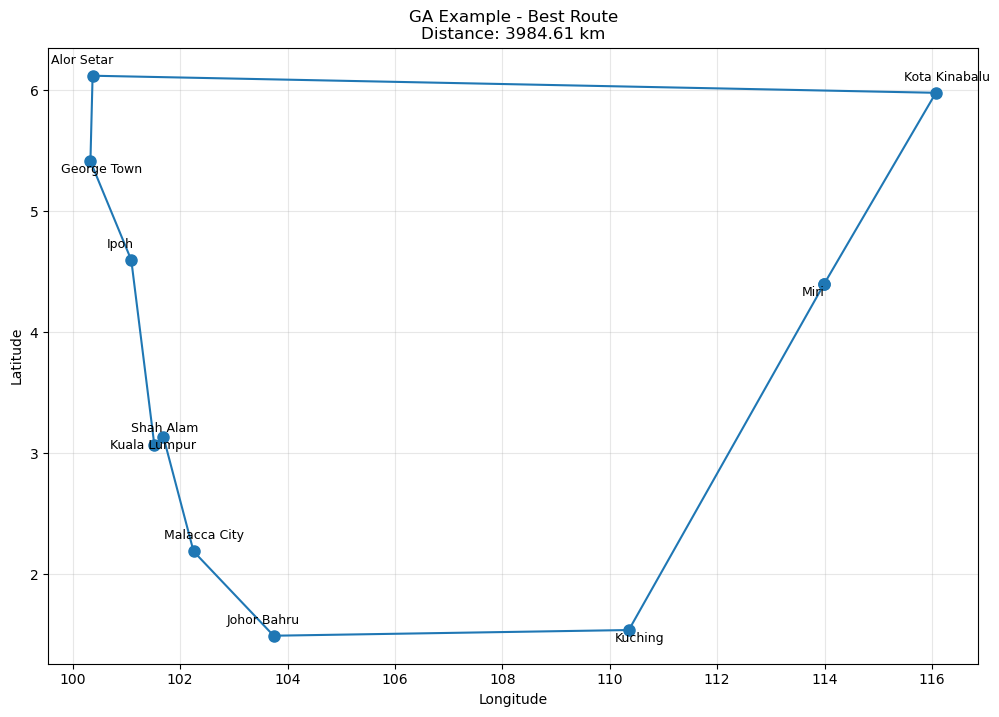


Running PSO example...


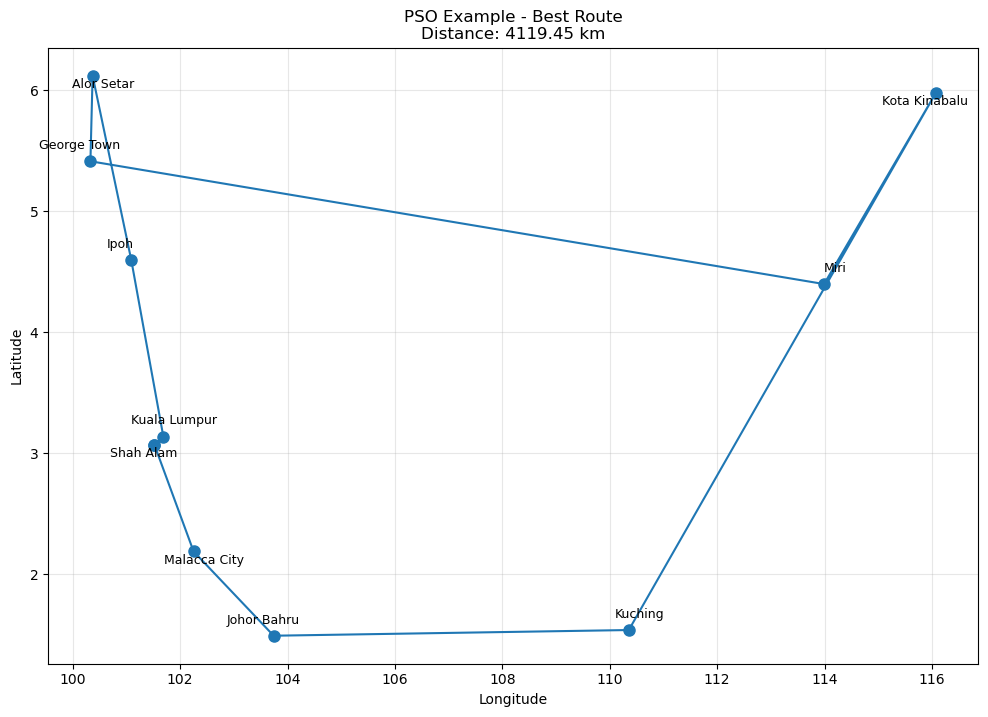

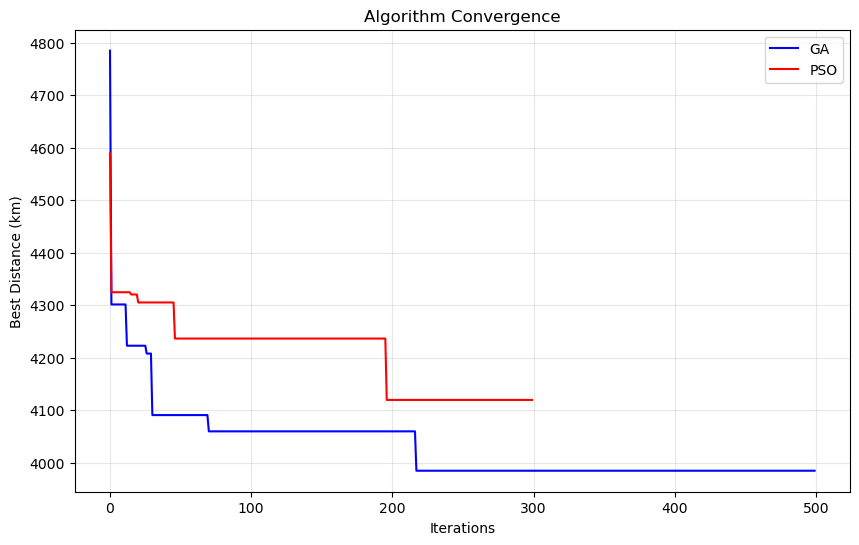

RUNNING COMPARISON (5 RUNS) WITH ROUTE VISUALIZATION

Run 1/5


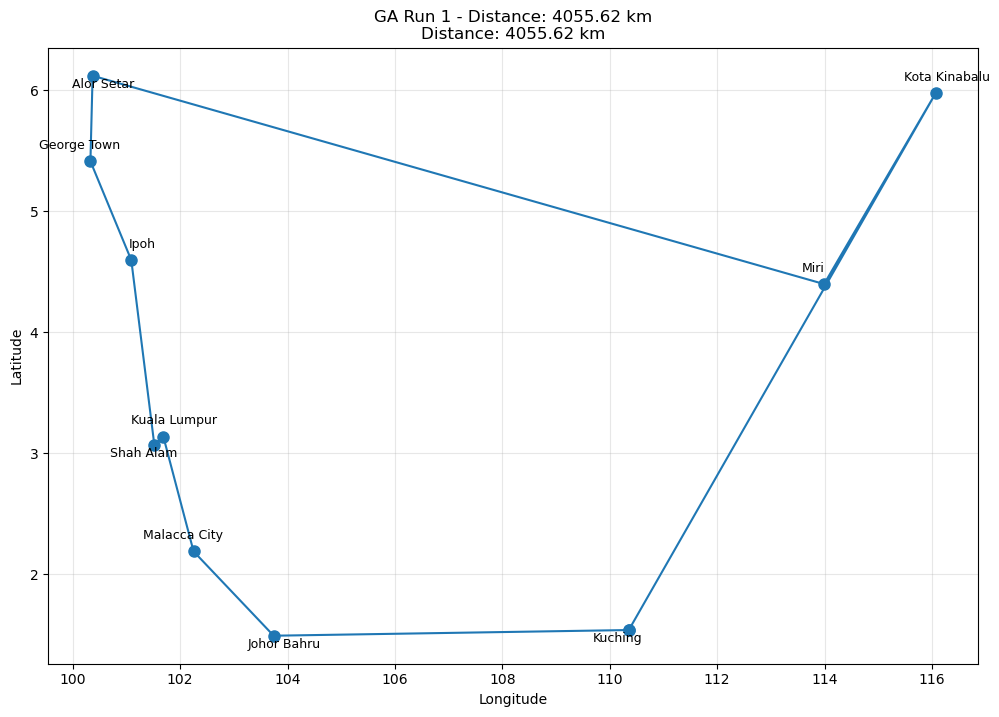

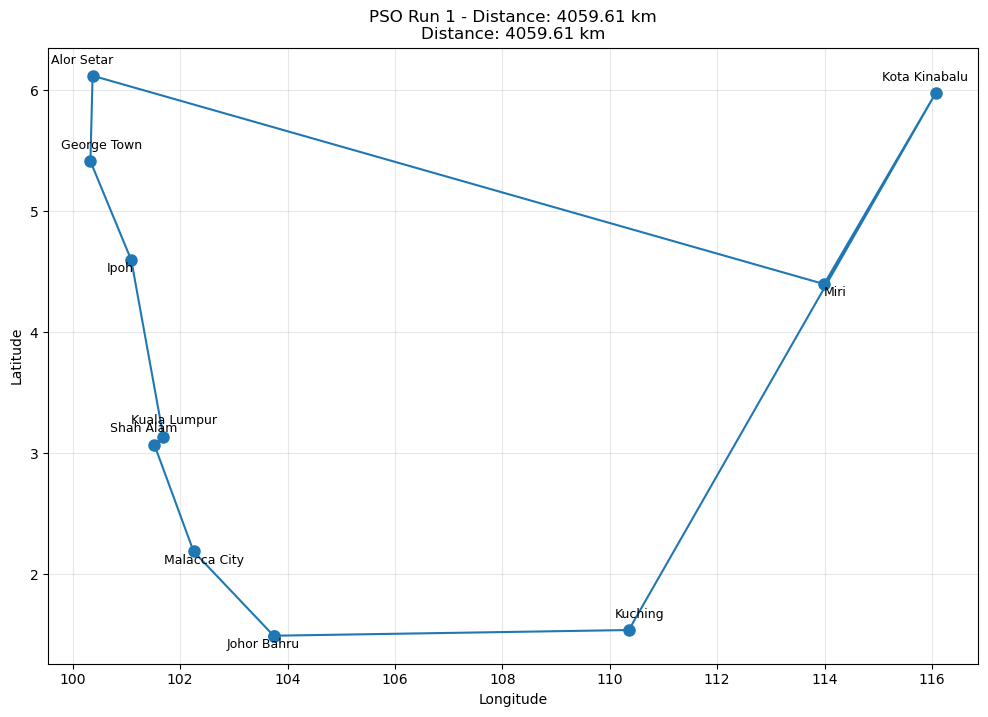

GA: 4055.62 km (464 gens) | PSO: 4059.61 km (104 iters)

Run 2/5


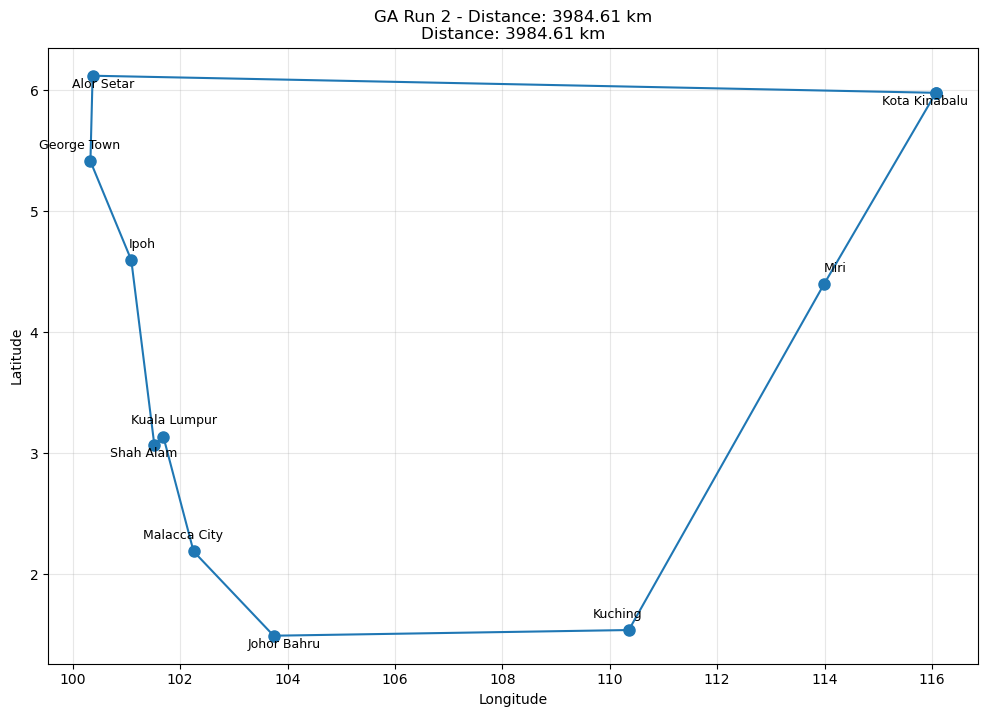

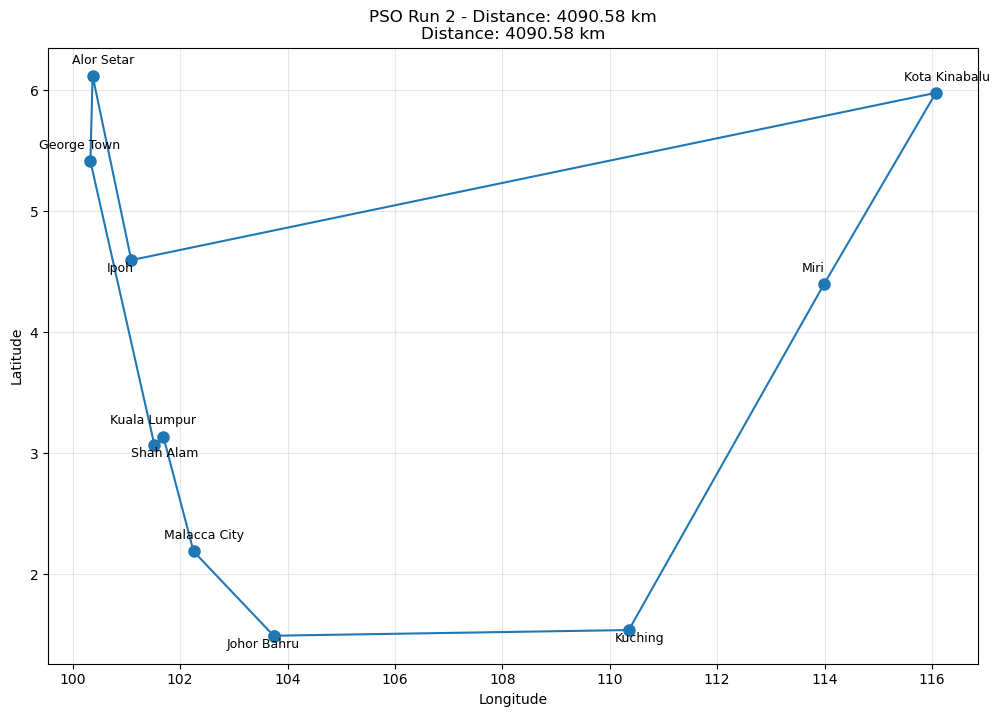

GA: 3984.61 km (132 gens) | PSO: 4090.58 km (126 iters)

Run 3/5


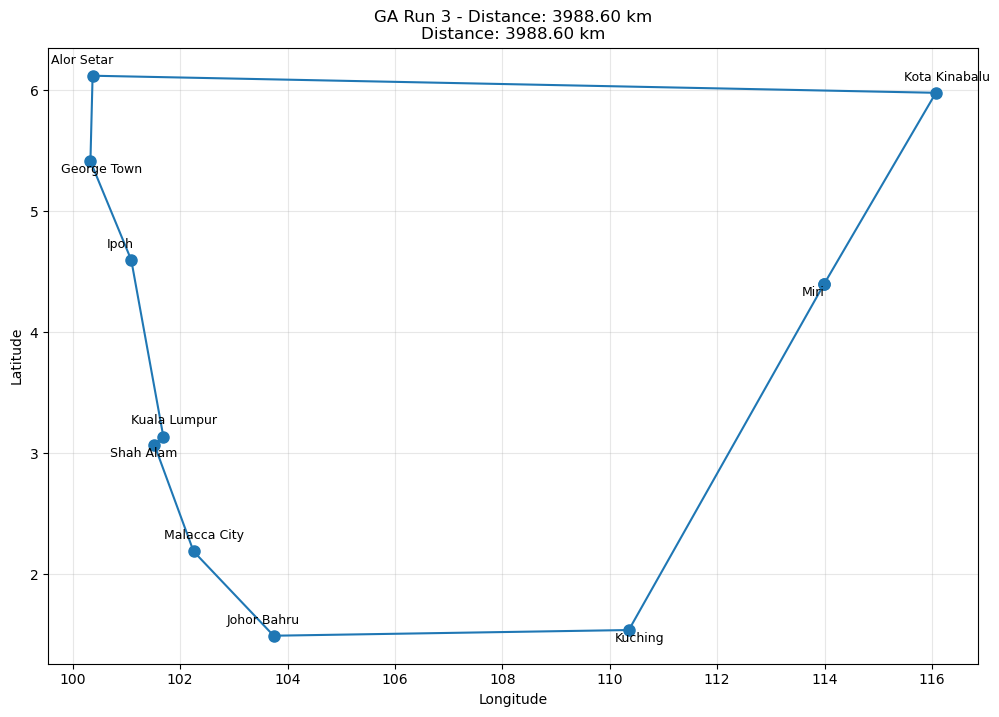

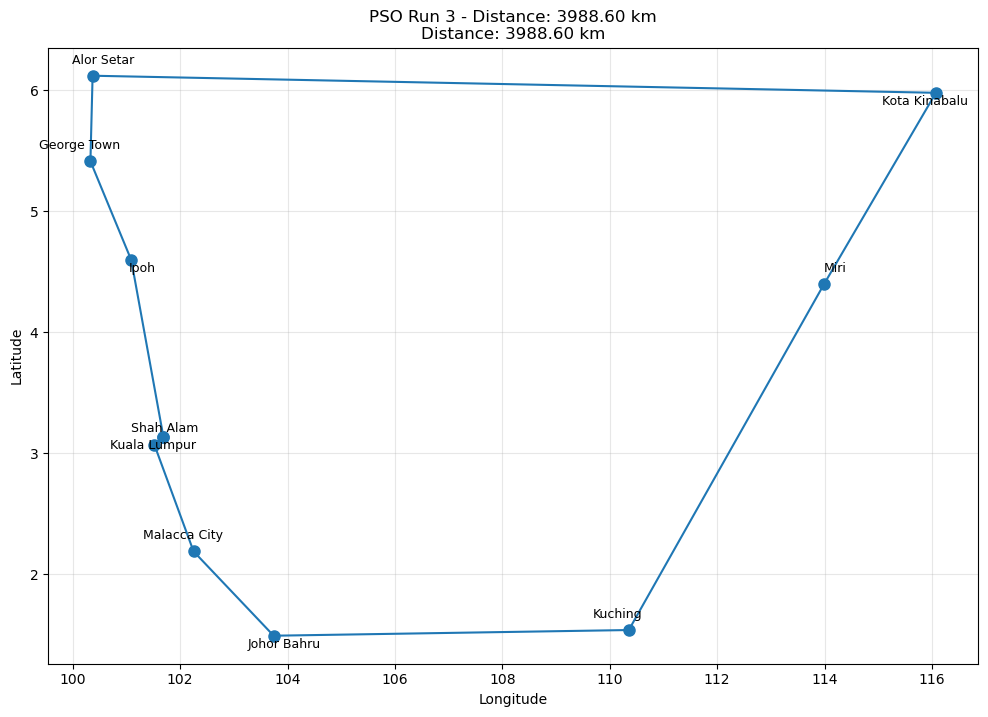

GA: 3988.60 km (354 gens) | PSO: 3988.60 km (167 iters)

Run 4/5


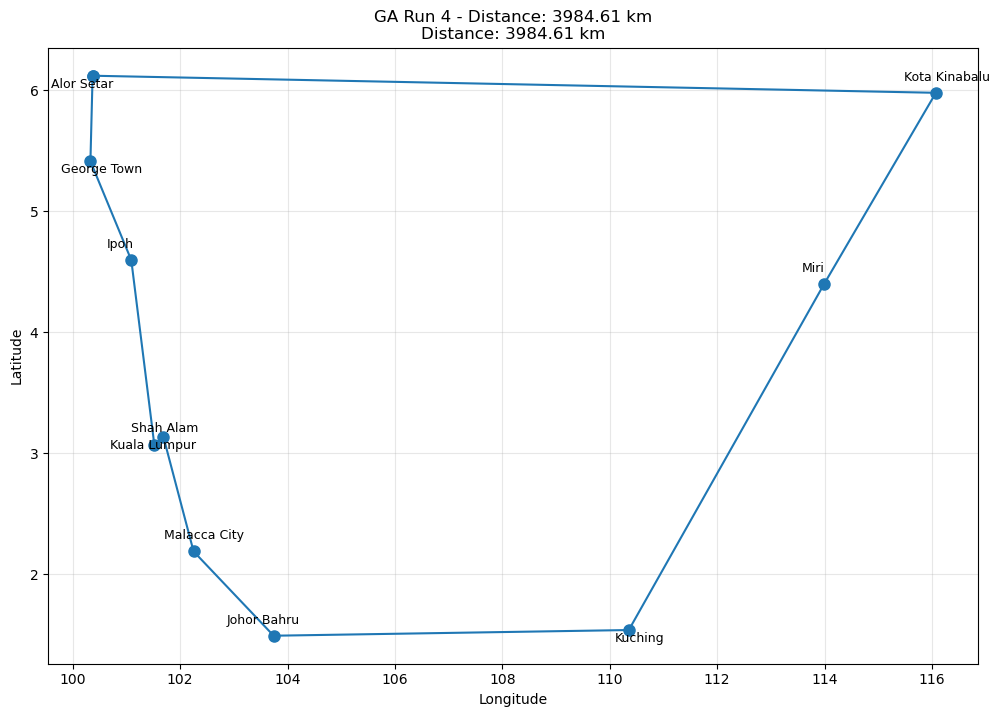

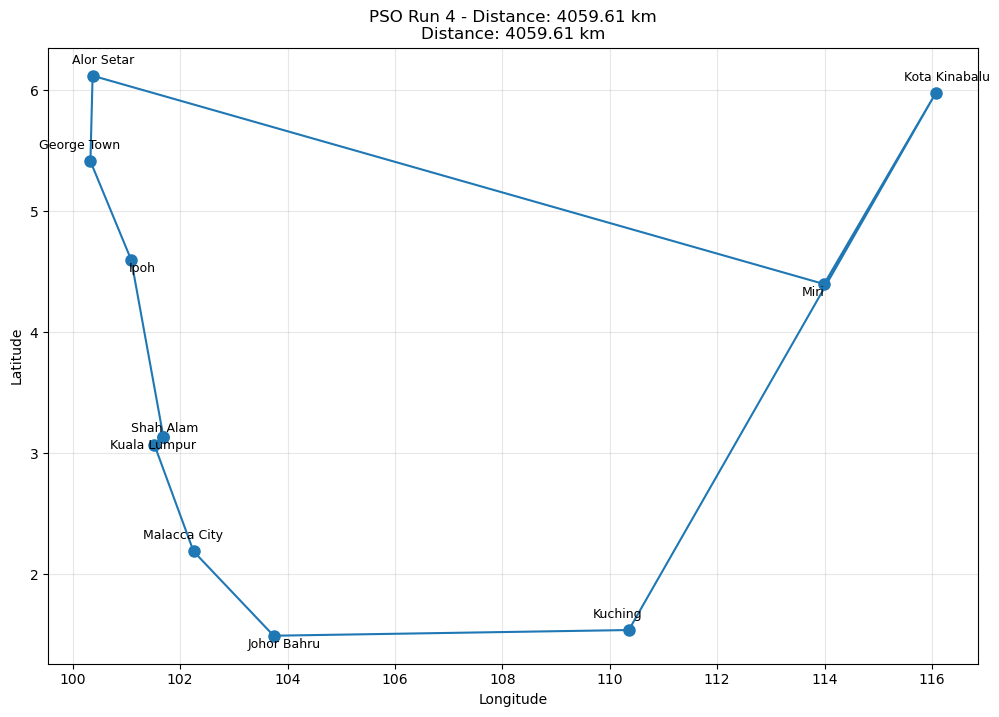

GA: 3984.61 km (356 gens) | PSO: 4059.61 km (175 iters)

Run 5/5


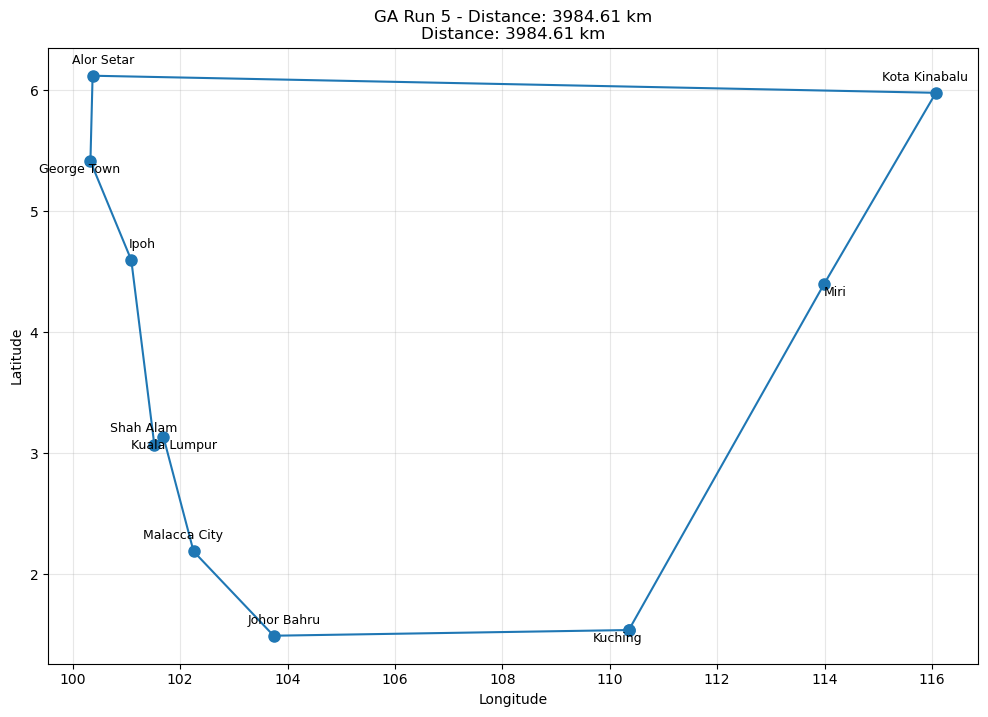

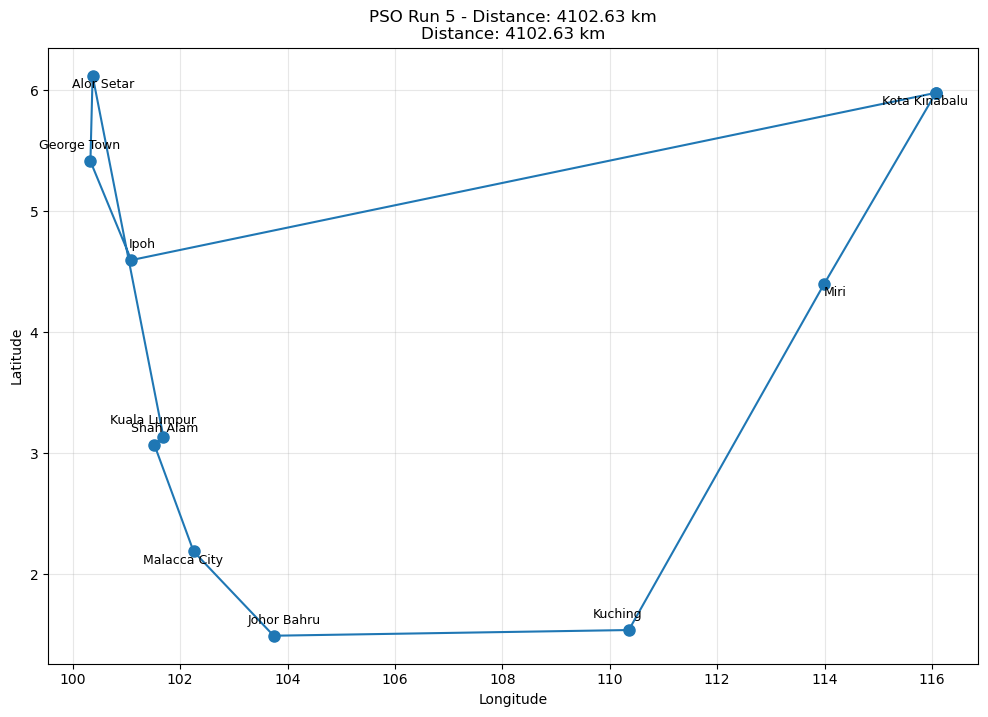

GA: 3984.61 km (160 gens) | PSO: 4102.63 km (284 iters)

 PERFORMANCE COMPARISON RESULTS

1. SHORTEST ROUTE FOUND
Algo     Best       Worst      Mean       Median     Std       
GA       3984.61    4055.62    3999.61    3984.61    28.05     
PSO      3988.60    4102.63    4060.21    4059.61    39.62     

2. CONVERGENCE ITERATIONS
Algo     Best       Worst      Mean       Median     Std       
GA       132        464        293.2      354.0      126.9     
PSO      104        284        171.2      167.0      62.2      

3. CONSISTENCY OVER RUNS
Algo     Best Dist  Worst Dist Range      Std Dev   
GA       3984.61    4055.62    71.01      28.05     
PSO      3988.60    4102.63    114.03     39.62     


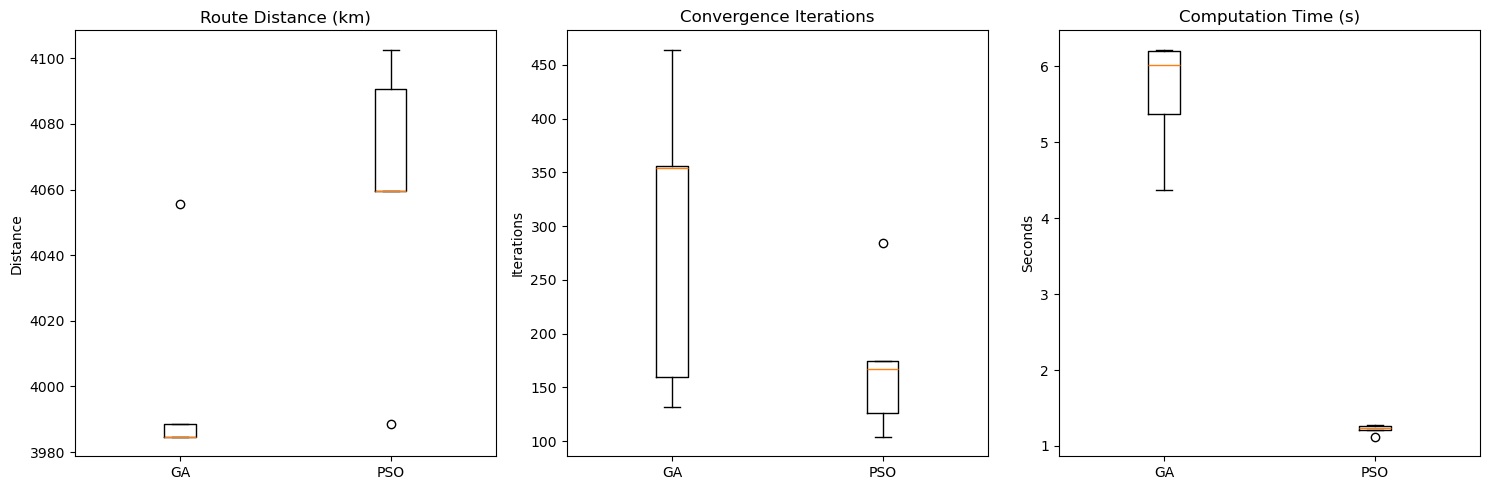

In [6]:
#5. MAIN EXECUTION WITH ROUTE VISUALIZATION
if __name__ == "__main__":
    # Run single example first
    print("Running GA example...")
    ga_route, ga_dist, _, ga_history = genetic_algorithm(verbose=True)
    plot_route(ga_route, "GA Example - Best Route")
    
    print("\nRunning PSO example...")
    pso_route, pso_dist, _, pso_history = particle_swarm_optimization(verbose=True)
    plot_route(pso_route, "PSO Example - Best Route")
    
    # Plot convergence comparison
    plt.figure(figsize=(10,6))
    plt.plot(ga_history, 'b-', label='GA')
    plt.plot(pso_history, 'r-', label='PSO')
    plt.title("Algorithm Convergence")
    plt.xlabel("Iterations")
    plt.ylabel("Best Distance (km)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    
    # Run full comparison with route visualization
    results, stats = run_comparison_with_route_visualization(num_runs=5)